# Week 6 · 02 Regularization: networks that work on new data

A network with thousands of weights can memorize a small training set and still be bad on new data. This notebook is about the four standard fixes: **weight decay** (keep the weights small), **dropout** (switch random units off while training), **early stopping** (stop when the validation loss stops improving) and **data augmentation** (make more training data). It starts from two finished networks on the same tiny dataset, one overfitted and one regularized. Reading: UDL (Prince) Ch. 9; d2l.ai §3.7 and §5.6.

**How to use this notebook**
- Run cells one at a time with **Shift + Enter**.
- Before running an example, **guess what it prints**. The real result is written after `# →` in the comments, so you can check yourself.
- **Your turn** cells are for you. Open **Show one answer** only after a real attempt.
- If things get weird, click **Restart** at the top and run from the top again.

## Words you'll see
- **overfitting**: fitting the training data so closely, noise included, that the model does worse on new data.
- **generalization**: how well a model does on data it never saw while training.
- **validation set**: data held out from training and used to make choices (when to stop, which settings). The test set is used once, at the very end.
- **regularization**: anything that makes a model generalize better, usually by limiting how freely it can fit the training data.
- **validation loss**: the loss on the validation set. Unlike accuracy, it also counts how confident the predictions are.

**Run this cell first.** It loads NumPy, the picture helpers (`figures.py` in this folder) and the exercise checker.

In [26]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from figures import *
import checks; checks.load(globals(), "02")      # defines check(n)

## M. The map: what's in this notebook and why

🖼 **Picture.** The whole notebook in one picture: the same network on the same 150 training images. Left, without regularization: the training loss falls towards 0 while the validation loss stops improving at epoch 58 and then slowly rises. Right, with weight decay and dropout: the two curves stay closer together, and the validation loss ends lower.

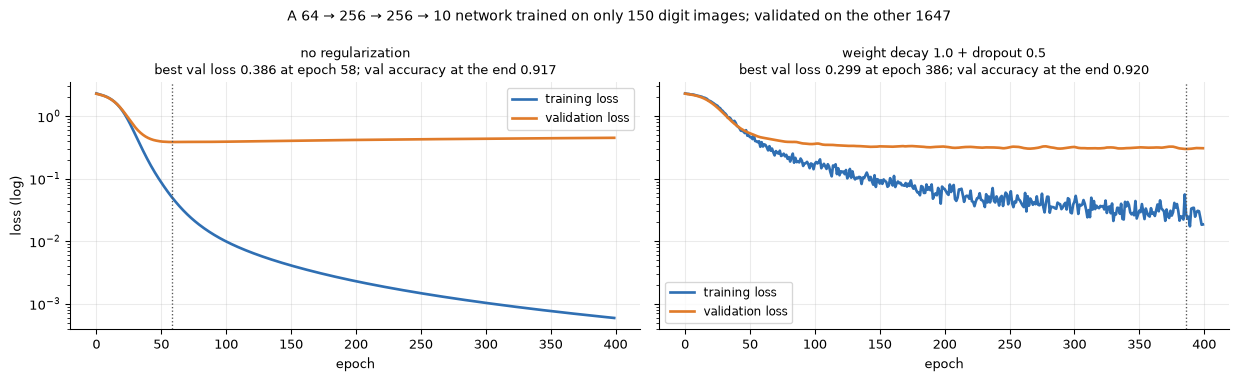

In [27]:
fig_overfit_curves()

| Section | What | Why it's here |
|---|---|---|
| 0 | recap, and booklet 1.8's ridge formula from memory | weight decay (§2) is ridge regression for networks |
| E | two finished networks, compared | start from the end: what regularization buys you |
| 1 | overfitting, in deep-learning words | training loss vs validation loss, and why big networks overfit small data |
| 2 | weight decay | keep the weights small; a proposition with its proof |
| 3 | dropout | switch random units off; why the scaling by $1/(1-p)$ |
| 4 | early stopping | keep the weights from the best epoch; an algorithm card |
| 5 | data augmentation | more training data for free |
| 6 | In Python | one block with all four, and exercises 2–4 from it |

## 0. Recap first · 10 min, closed book

**Quick check:** Ridge regression minimizes what, and what does the penalty do to the weights?

<details><summary>Answer</summary>

$\lVert y - Xw \rVert^2 + \lambda \lVert w \rVert^2$. The penalty pulls every weight towards 0 (none becomes exactly 0; that's lasso). [Week 2 · 04 §7 ↗](../week2/04_ml_intro_linear_regression.ipynb)

</details>

**Quick check:** Ridge as MAP: which prior on the weights gives the ridge penalty?

<details><summary>Answer</summary>

A Gaussian prior centred at 0: $w_j \sim \mathcal{N}(0, \tau^2)$. Its $-\log$ is $\frac{w_j^2}{2\tau^2} + \text{const}$. [Week 2 · 02 §4 ↗](../week2/02_map_and_entropy_in_depth.ipynb)

</details>

**Quick check:** Training, validation, test: what is each set for?

<details><summary>Answer</summary>

Training: fit the weights. Validation: make choices (settings, when to stop). Test: one final, honest score. [Week 1 · 03 §8 ↗](../week1/03_math_essentials.ipynb)

</details>

**Quick check:** `model.train()` vs `model.eval()`: which layers behave differently?

<details><summary>Answer</summary>

Dropout and batch normalization. [Week 5 · 06 §7 ↗](../week5/06_pytorch_basics.ipynb)

</details>

**Quick check:** A model gets 100% on training data and 70% on test data. Bias or variance problem?

<details><summary>Answer</summary>

Variance (overfitting): it fits the training data too closely. [Week 1 · 03 §8 ↗](../week1/03_math_essentials.ipynb)

</details>

**Exercise 1 · Booklet 1.8: ridge regression, closed form.** $w = (X_1^\top X_1 + \lambda P)^{-1} X_1^\top y$, where $P$ is the identity matrix with $P_{00} = 0$, so the intercept isn't penalized. `X1` is `(n, d+1)` with a first column of 1s. Use `np.linalg.solve(A, b)` (it solves $Aw = b$) rather than an inverse. Return `w`, **shape `(d+1,)`**.

**Example**: what goes in, and what should come out:
```python
X1 = np.array([[1.0, -1.0], [1.0, 0.0], [1.0, 1.0]]); y = np.array([-2.0, 0.0, 2.0])    # y = 2x
ridge_closed_form(X1, y, 0.0)    # → [0. 2.]
ridge_closed_form(X1, y, 2.0)    # → [0. 1.]   the slope shrinks from 2 to 4 / (2 + 2) = 1
```

In [28]:
def ridge_closed_form(X1, y, lam):                    # booklet 1.8
    P = np.eye(X1.shape[1])
    P[0, 0] = 0                                       
    return np.linalg.solve(X1.T @ X1 + lam * P, X1.T @ y)

In [29]:
check(1)

Exercise 1: PASS


## E. Start from the end: two finished networks

Both networks are $64 \to 256 \to 256 \to 10$ with ReLU (about 83,000 weights), trained for 400 epochs on **only 150** of the 1797 digit images; the other 1647 are the validation set. The only difference is regularization:

|  | No regularization | Weight decay 1.0 + dropout 0.5 |
|---|---|---|
| training accuracy | 1.000 | 1.000 |
| training loss at the end | 0.0006 | 0.0185 |
| validation accuracy | 0.917 | 0.920 |
| validation loss at the end | 0.450 | 0.307 |
| best validation loss (epoch) | 0.386 (58) | 0.299 (386) |

**How to read it.** Both get every training image right. The first network's training loss is almost 0: it's **sure** about every training image, including the odd ones, and that certainty doesn't carry over: its validation loss is 50% higher. Accuracy only moves a little here (0.917 vs 0.920), because accuracy only checks whether the top class is right; the loss also counts how confident the model is when it's wrong, and that's where the difference shows. On harder problems, with less clean data, the accuracy gap is usually larger.

**The rest of this notebook answers:** what exactly do weight decay and dropout do to the network, why do they help, and what are the other two tools (early stopping, augmentation)?

## 1. Overfitting, in deep-learning words

**The problem.** 150 images and 83,000 weights: there are far more knobs than facts to fit. The network can find weights that fit all 150 images exactly, including whatever is special about each one (a stroke drawn a bit thick, a smudge). That's **memorizing**, and it doesn't help on new images.

**How you see it.** Watch two curves during training (the picture in §M): the **training loss** (on the data the network learns from) and the **validation loss** (on held-out data). Early on, both fall: the network is learning real patterns. Later the training loss keeps falling but the validation loss stalls or rises: the network is now fitting noise. The distance between the curves is the **generalization gap**.

| What you see | What it means | What to do |
|---|---|---|
| both losses high | underfitting: the model hasn't learned enough | train longer, a bigger model, a better learning rate |
| training low, validation much higher, and rising | overfitting | regularize (§2–5), or get more data |
| both low and close | good | test once on the test set, and stop |

**In one sentence:** overfitting is when the training loss keeps going down but the validation loss doesn't, because the model is learning the training set's noise.

## 2. Weight decay: keep the weights small

**The problem.** Fitting noise usually needs **large** weights: to bend the function sharply around individual training points. A network with small weights computes a smoother function.

**The idea.** Add a penalty for large weights to the loss, exactly as ridge regression does: the network then has to "pay" for every bit of weight it uses, and only uses it where it really lowers the loss.

**The formula, piece by piece.**

$$
L_{\text{total}}(w) = \underbrace{L(w)}_{\text{the usual loss}} + \underbrace{\frac{\lambda}{2}\lVert w \rVert^2}_{\text{the penalty}}, \qquad \lVert w \rVert^2 = \sum_j w_j^2
$$

- $L(w)$ is the cross-entropy, as before.
- $\lVert w \rVert^2$ adds up the square of every weight in the network (biases are usually left out).
- $\lambda$ ("lambda", a hyperparameter) sets how much large weights cost. $\lambda = 0$ is no regularization.
- The $\frac{1}{2}$ is only there to make the derivative tidy: $\frac{d}{dw}\frac{\lambda}{2}w^2 = \lambda w$.

🖼 **Picture.** Left: with the penalty $\lambda w^2$ added to the loss $(w - 2)^2$, the best weight moves from 2 towards 0. Right: why it's called *decay*: each step multiplies every weight by $(1 - \eta\lambda)$ before the usual gradient step.

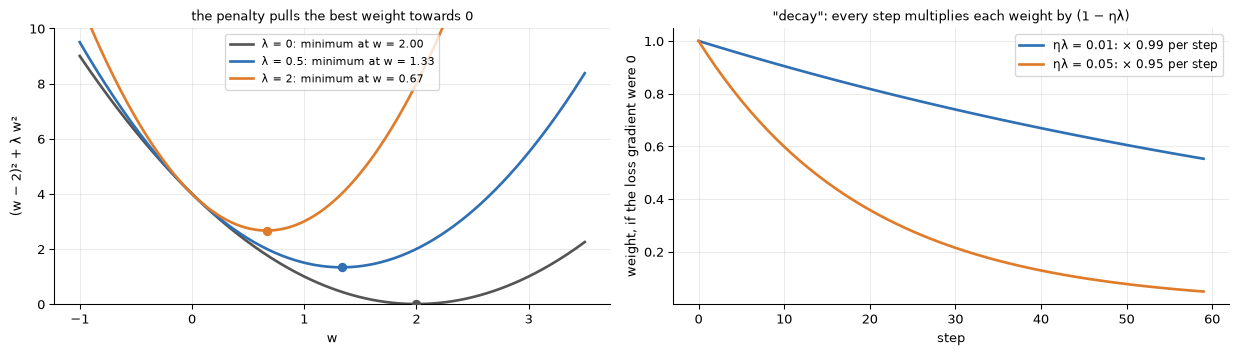

In [30]:
fig_weight_decay()

### Setup

Add an L2 penalty to the original loss $L(\mathbf{w})$:

$$\tilde{L}(\mathbf{w}) = L(\mathbf{w}) + \frac{\lambda}{2}\|\mathbf{w}\|^2$$

The $\frac{1}{2}$ is only there so the derivative comes out clean.

### Gradient

$$\nabla \tilde{L}(\mathbf{w}) = \nabla L(\mathbf{w}) + \lambda \mathbf{w}$$

The derivative of $\frac{\lambda}{2}\|\mathbf{w}\|^2 = \frac{\lambda}{2}\sum_i w_i^2$ with respect to $w_i$ is $\lambda w_i$.

### Gradient step

With learning rate $\eta$:

$$\mathbf{w}_{t+1} = \mathbf{w}_t - \eta\big(\nabla L(\mathbf{w}_t) + \lambda \mathbf{w}_t\big)$$

Group the $\mathbf{w}_t$ terms:

$$\boxed{\mathbf{w}_{t+1} = (1 - \eta\lambda)\,\mathbf{w}_t \;-\; \eta\,\nabla L(\mathbf{w}_t)}$$

Read it in two parts:

1. **Decay:** shrink every weight by the factor $(1 - \eta\lambda)$, which is slightly less than 1.
2. **Usual step:** take the ordinary gradient step on the original loss.


**Proposition.** One gradient descent step on $L_{\text{total}}$ is the same as first shrinking every weight by the factor $(1 - \eta\lambda)$ and then taking the usual step on $L$:

$$
w \leftarrow (1 - \eta\lambda)\, w - \eta\, \nabla L(w)
$$

**What it says, in words.** Every step, each weight loses a fixed fraction $\eta\lambda$ of itself (it "decays" towards 0), and then the gradient pushes it wherever the data wants. A weight that the data doesn't keep pushing up slowly fades away.

**A small example.** $w = 2$, gradient $\nabla L = 0.5$, $\eta = 0.1$, $\lambda = 0.5$. Shrink: $(1 - 0.1 \times 0.5) \times 2 = 0.95 \times 2 = 1.9$. Step: $1.9 - 0.1 \times 0.5 = 1.85$. Without decay it would have been $2 - 0.05 = 1.95$.

**The proof in plain words.** The penalty's slope is $\lambda w$, so the total slope is $\nabla L + \lambda w$. Plug that into the usual update and collect the $w$ terms:

$$
w - \eta\big(\nabla L(w) + \lambda w\big) = w - \eta\lambda w - \eta \nabla L(w) = (1 - \eta\lambda)\, w - \eta\, \nabla L(w). \qquad \blacksquare
$$

**Remark 1: it's ridge regression for networks.** With a linear model and squared error, this is exactly your booklet's ridge (exercise 1). And it's MAP with a Gaussian prior on the weights (Week 2): we believe, before seeing data, that weights are probably small.

**Remark 2: in PyTorch.** `torch.optim.SGD(params, lr, weight_decay=λ)` adds $\lambda w$ to every gradient, which is the proposition exactly. For Adam, adding $\lambda w$ to the gradient doesn't work as well, because Adam divides every gradient by its typical size, which also shrinks the decay. **AdamW** fixes this by applying the shrinking directly to the weights, separately from the Adam step: $w \leftarrow w - \eta\lambda w$, then the Adam update. Use AdamW whenever you want weight decay with Adam.

**Remark 3: choosing $\lambda$.** Too small and nothing changes; too large and the weights can't grow enough to fit even the real patterns (underfitting). Pick it with the validation set, trying values like $10^{-4}, 10^{-3}, \dots$; for AdamW, typical values are 0.01 to 1.

In [31]:
w = torch.tensor([2.0, -1.0], requires_grad=True)
opt = torch.optim.SGD([w], lr=0.1, weight_decay=0.5)
(0.5 * w[0] + 0.25 * w[1]).backward()           # a loss whose gradient is (0.5, 0.25)
opt.step()
print(w.detach().numpy(), 0.95 * np.array([2.0, -1.0]) - 0.1 * np.array([0.5, 0.25]))   # → [ 1.85  -0.975] [ 1.85  -0.975]

[ 1.85  -0.975] [ 1.85  -0.975]


**In one sentence:** weight decay adds $\frac{\lambda}{2}\lVert w \rVert^2$ to the loss, which makes every step shrink each weight by a factor $(1 - \eta\lambda)$ before the usual update.

## 3. Dropout: switch random units off

**The problem.** In a big network, units can come to depend on each other's quirks: unit 7 is only useful because unit 12 makes a particular mistake on certain training images. Such fragile teamwork fits the training set and breaks on new data (this is called co-adaptation).

**The idea.** During training, switch off each hidden unit at random, with probability $p$, independently at every step. Like a team where anyone might be absent on a given day: everyone has to be useful on their own, and no one can rely on one particular colleague. At test time, everyone is present.

🖼 **Picture.** $p = 0.5$: in each training step a different random half of the hidden units is off (×), so each step trains a different thinned network. When testing, every unit is on.

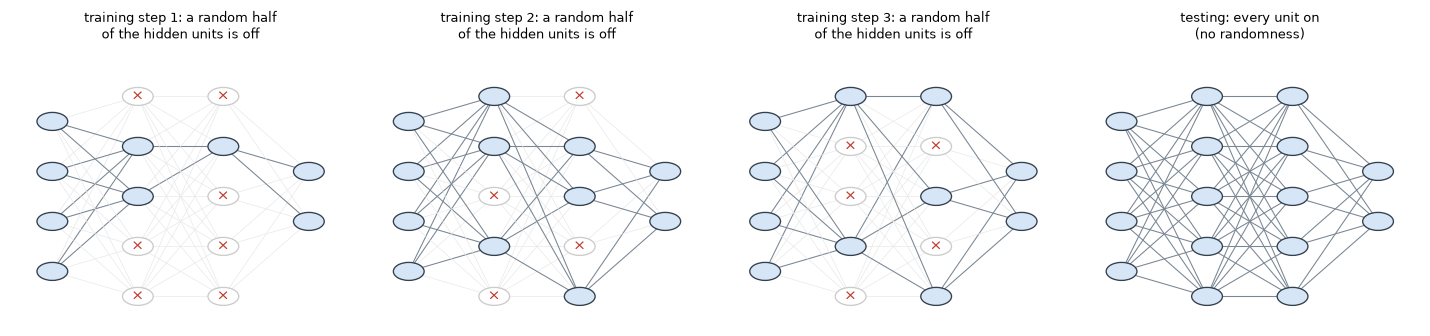

In [32]:
fig_dropout_masks()

**The formula, piece by piece.** For a layer's output $h$ (one value per unit), during training:

$$
m_i \sim \text{Bernoulli}(1 - p), \qquad \tilde h_i = \frac{m_i\, h_i}{1 - p}
$$

- $m_i$ is a random 0 or 1: 1 (keep) with probability $1 - p$, 0 (drop) with probability $p$. A new $m$ is drawn at every step.
- $m_i h_i$ is $h_i$ if the unit is kept, 0 if it's dropped.
- Dividing by $1 - p$ makes the kept units larger, to make up for the missing ones (the proposition says exactly how). This version is called *inverted* dropout; it's what PyTorch does.
- At test time: $\tilde h = h$. No mask, no scaling.

It fixes a **scale mismatch between training and test time**, and moves the correction into training so the test-time network doesn't need any changes.

### The problem with plain dropout

During training, each unit is kept with probability $q$ and zeroed otherwise:

$$\tilde{a} = m \cdot a, \qquad m \sim \text{Bernoulli}(q)$$

The expected output of that unit is

$$\mathbb{E}[\tilde{a}] = q\,a$$

At test time dropout is switched off and every unit is active, so the unit outputs the full $a$.

So the next layer sees inputs that are on average **$1/q$ times larger at test time than in training**. Its weights were learned for the smaller training-time scale. For example, with $q = 0.5$ the next layer receives about twice the total input it was trained on. The pre-activations shift, and the predictions are off.

### Inverted dropout

Do the correction **during training** instead, by dividing the kept units by $q$:

$$\tilde{a} = \frac{m}{q}\,a, \qquad m \sim \text{Bernoulli}(q)$$

Now

$$\mathbb{E}[\tilde{a}] = \frac{q\,a}{q} = a$$

The expected activation in training is exactly what the unit outputs at test time, so **inference is just the plain network with no scaling and no knowledge of $q$**. Dropout becomes an identity operation at test time. That is what `model.eval()` does in PyTorch.

Example with $q = 0.5$: a unit with $a = 4$ outputs 8 half the time and 0 the other half during training, for an average of 4. At test time it outputs 4.

### What it doesn't fix

- **It only matches the mean, not the distribution.** The training-time activation has extra variance, $\text{Var}[\tilde{a}] = a^2\frac{1-q}{q}$, while the test-time one has none. This is one reason dropout and BatchNorm interact badly: BatchNorm's running statistics are collected under dropout's noisier activations.
- **Matching the mean is exact only through linear operations.** After a nonlinearity, $\mathbb{E}[\sigma(\cdot)] \neq \sigma(\mathbb{E}[\cdot])$, so the deterministic test-time network only approximates averaging over all the thinned networks. Plain dropout's weight-scaling has the same limitation, so inverted dropout is no worse here. It's just cleaner.

**A small example.** $h = (2, 4, 6, 8)$, $p = 0.5$, and this step's mask happens to be $m = (1, 0, 1, 0)$. Then $\tilde h = (2, 0, 6, 0) / 0.5 = (4, 0, 12, 0)$. Over many steps, unit 1 is $0$ half the time and $4$ the other half: $2$ on average, its original value.

**Proposition.** The expected value of each output is unchanged by dropout: $\mathbb{E}[\tilde h_i] = h_i$.

**What it says, in words.** On average, the next layer receives the same values it would get with no dropout, so it sees the same scale in training and in testing. That's why testing needs no correction.

**The proof in plain words.** $\tilde h_i$ takes only two values: $h_i / (1 - p)$ (with probability $1 - p$) and $0$ (with probability $p$). Its average is the first value times its probability:

$$
\mathbb{E}[\tilde h_i] = (1 - p) \cdot \frac{h_i}{1 - p} + p \cdot 0 = h_i. \qquad \blacksquare
$$

**Remark 1: why not just drop without scaling?** Then the next layer would receive $(1 - p)$ times smaller values while training than while testing, and its weights would be tuned for the wrong scale.

**Remark 2: what it means.** Each step trains a different thinned network, and all of them share weights. Testing with all units on is roughly the average of all those networks: an ensemble, like bagging (Week 3), for the price of one network.

**Remark 3: in practice.** Put `nn.Dropout(p)` after the activation of hidden layers, with $p$ between 0.1 and 0.5; never on the output. Remember `model.eval()` before testing, or the randomness stays on (Week 5 · 07 III5).

In [33]:
torch.manual_seed(0)
drop = nn.Dropout(p=0.5)                 # starts in training mode
h = torch.tensor([2.0, 4.0, 6.0, 8.0])
print(drop(h))                           # → tensor([ 0.,  0., 12.,  0.])   this step: only unit 2 survives, doubled
print(drop(h.expand(200000, 4)).mean(dim=0).round(decimals=2))   # → tensor([2.0100, 3.9800, 6.0000, 8.0300])   200,000 random masks: on average, h
drop.eval()
print(drop(h))                           # → tensor([2., 4., 6., 8.])   testing: unchanged

tensor([ 0.,  0., 12.,  0.])
tensor([2.0100, 3.9800, 6.0000, 8.0300])
tensor([2., 4., 6., 8.])


**In one sentence:** dropout zeroes each hidden unit with probability $p$ during training and scales the survivors by $1/(1-p)$, so the average is unchanged and nothing needs fixing at test time.

## 4. Early stopping: keep the best epoch

**The problem.** The validation loss usually falls, bottoms out, then creeps up as the network starts fitting noise (§M, left). Training to the end gives you the late, overfitted weights.

**The idea.** Watch the validation loss after every epoch, remember the weights from the best epoch so far, and stop once it hasn't improved for a while.

**Algorithm card: early stopping**

**Goal.** The weights with the lowest validation loss, without training longer than needed.

- Before training: best loss $= \infty$, best epoch $= 0$; choose a **patience** $P$ (e.g. 20 epochs).
- After each epoch $t$: compute the validation loss $v_t$.
- If $v_t$ is below the best so far: it's the new best; save a copy of the weights (`copy.deepcopy(model.state_dict())`) and set the best epoch to $t$.
- Otherwise, if $t - \text{best epoch} \ge P$: stop.
- At the end, load the saved best weights back into the model.

**Why it works.** The epoch with the lowest validation loss is the best estimate of when the network stopped learning real patterns. **Caveats:** the validation loss is noisy, which is why we wait $P$ epochs instead of stopping at the first rise; and the choice uses the validation set, so the final score must come from the separate test set. **Cost:** one validation pass per epoch, and it usually *saves* training time.

**A tiny trace**, validation losses $(0.9, 0.7, 0.6, 0.65, 0.62, 0.7, 0.8)$ with patience 3:

| epoch $t$ | $v_t$ | new best? | epochs since best | action |
|---|---|---|---|---|
| 0 | 0.9 | yes | 0 | save |
| 1 | 0.7 | yes | 0 | save |
| 2 | 0.6 | yes | 0 | save |
| 3 | 0.65 | no | 1 |  |
| 4 | 0.62 | no | 2 |  |
| 5 | 0.7 | no | 3 | **stop**, load epoch 2's weights |

🖼 **Picture.** On the unregularized network from §E: the best validation loss is at epoch 58; with patience 20, training stops at epoch 78 and goes back to epoch 58's weights.

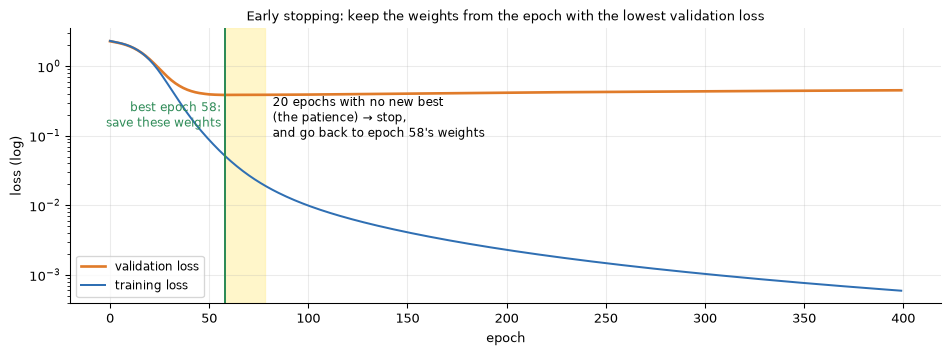

In [34]:
fig_early_stopping()

**In one sentence:** early stopping keeps the weights from the epoch with the lowest validation loss and stops once that hasn't improved for a set number of epochs.

## 5. Data augmentation: more data for free

**The problem.** The most reliable cure for overfitting is more data, and data is expensive.

**The idea.** Make new training images from the ones you have, by changes that don't change the label: shift the digit a pixel, rotate it a little, add a bit of noise. A slightly rotated 3 is still a 3. The network sees many versions of each image and can't memorize any one of them; it also learns that these changes don't matter.

🖼 **Picture.** One training image of a "0" and five augmented copies, all labelled "0".

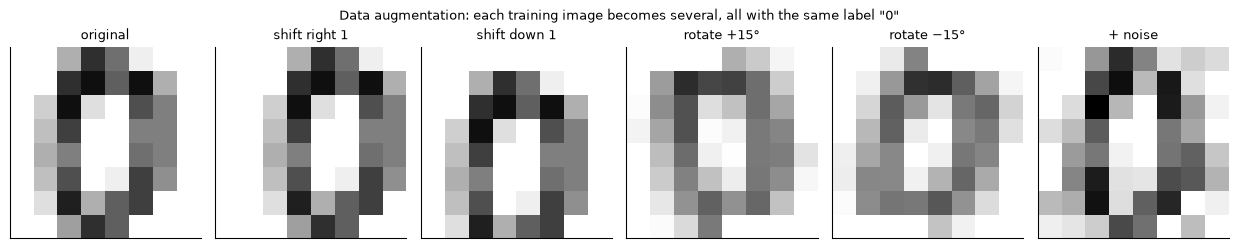

In [35]:
fig_augment()

**Caveat: the change must keep the label true.** Rotating a 6 by 180° makes a 9; flipping a photo of a cat left to right is fine, flipping the digit 2 isn't. In PyTorch, augmentation is part of the dataset's `transform`, e.g. `transforms.RandomAffine(degrees=15, translate=(0.1, 0.1))`, and it draws a new random change every time an image is loaded, so every epoch sees different versions.

**In one sentence:** augmentation multiplies the training data with label-preserving changes, and it's usually the most effective regularizer for images.

## 6. In Python: all four in one block

The block below is written like your booklet's "In Python" sections: one dataset, the loop by hand, PyTorch for the layers (`nn.Dropout`) and the optimizer (`AdamW`'s `weight_decay`), and early stopping written out. It's ready to become the "In Python" of a booklet chapter on regularization.

In [36]:
import copy
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

X, y = load_digits(return_X_y=True) # return_X_y=True assigns data & target to X & y respectively.
X_tr, X_va, y_tr, y_va = train_test_split(X / 16, y, train_size=150, stratify=y, random_state=0) #X / 16: rescale pixels to [0, 1] 
X_tr, X_va = torch.tensor(X_tr, dtype=torch.float32), torch.tensor(X_va, dtype=torch.float32)
y_tr, y_va = torch.tensor(y_tr), torch.tensor(y_va)
loss_fn = nn.CrossEntropyLoss()

def fit(p_drop=0.0, weight_decay=0.0, patience=None, epochs=400):
    torch.manual_seed(0)
    net = nn.Sequential(nn.Linear(64, 256), nn.ReLU(), nn.Dropout(p_drop),     # dropout after each hidden activation
                        nn.Linear(256, 256), nn.ReLU(), nn.Dropout(p_drop), nn.Linear(256, 10))
    opt = torch.optim.AdamW(net.parameters(), lr=1e-3, weight_decay=weight_decay)   # weight decay, the AdamW way
    best, best_state, best_epoch = np.inf, None, 0
    for epoch in range(epochs):
        net.train()                                    # dropout on
        loss = loss_fn(net(X_tr), y_tr)                # all 150 images as one batch
        opt.zero_grad(); loss.backward(); opt.step()
        net.eval()                                     # dropout off, to measure
        with torch.no_grad():
            val = loss_fn(net(X_va), y_va).item()
        if val < best:                                 # early stopping: remember the best epoch
            best, best_state, best_epoch = val, copy.deepcopy(net.state_dict()), epoch
        elif patience is not None and epoch - best_epoch >= patience:
            break
    if patience is not None:
        net.load_state_dict(best_state)                # go back to the best weights
    net.eval()
    with torch.no_grad():
        acc = (net(X_va).argmax(dim=1) == y_va).float().mean().item()
        val = loss_fn(net(X_va), y_va).item()
    return round(acc, 3), round(val, 3), epoch

for name, settings in [("plain", {}), ("weight decay", dict(weight_decay=1.0)), ("dropout", dict(p_drop=0.5)),
                       ("both", dict(weight_decay=1.0, p_drop=0.5)), ("early stopping", dict(patience=20))]:
    print(f"{name:15}", fit(**settings))           # (validation accuracy, validation loss, last epoch)
# → plain           (0.917, 0.45, 399)
#   weight decay    (0.921, 0.343, 399)
#   dropout         (0.923, 0.358, 399)
#   both            (0.92, 0.307, 399)
#   early stopping  (0.899, 0.386, 78)

plain           (0.917, 0.45, 399)
weight decay    (0.921, 0.343, 399)
dropout         (0.923, 0.358, 399)
both            (0.92, 0.307, 399)
early stopping  (0.899, 0.386, 78)


**Reading the output.** Every regularizer lowers the validation loss compared with the plain network (0.45), and weight decay plus dropout together lower it most (0.307). Early stopping stops at epoch 78 and returns epoch 58's weights: their validation loss (0.386) is lower than the plain network's final 0.45, but their accuracy is slightly lower, because at epoch 58 the network was still a little underfitted. That's typical: early stopping alone is cheap and safe, and combining it with weight decay or dropout is common.

Exercises 2–4 are the three hand-written pieces this block relies on, so that you can write them on paper.

**Exercise 2 · One SGD step with weight decay.** Return $w - \eta(g + \lambda w)$, the update of §2 (what `torch.optim.SGD(..., weight_decay=λ)` does). `w`, `g` are arrays of the same shape; `lr` is $\eta$ and `lam` is $\lambda$. The check compares with PyTorch's optimizer.

**Example**: what goes in, and what should come out:
```python
sgd_weight_decay_step(np.array([2.0, -1.0]), np.array([0.5, 0.25]), 0.1, 0.5)    # → [ 1.85  -0.975]
```

In [37]:
def sgd_weight_decay_step(w, g, lr, lam):
    return w-lr*(g+lam*w)

In [38]:
check(2)

Exercise 2: PASS


**Exercise 3 · Inverted dropout.** Make the mask with `mask = rng.random(h.shape) >= p` (True = keep, probability $1 - p$), and return `(h * mask / (1 - p), mask)`. Using `rng` exactly this way lets the check reproduce your mask.

**Example**: what goes in, and what should come out:
```python
out, mask = inverted_dropout(np.array([2.0, 4.0, 6.0, 8.0]), 0.5, np.random.default_rng(0))
mask    # → [ True False False False]
out     # → [4. 0. 0. 0.]
```

In [39]:
def inverted_dropout(h, p, rng):
    mask = rng.random(h.shape) >= p 
    return (h*mask)/(1-p), mask

In [40]:
check(3)

Exercise 3: PASS


**Exercise 4 · Early stopping.** `val_losses` lists the validation loss after each epoch. Walk through them as in §4's card and return `(stop_epoch, best_epoch)`: the epoch where you'd stop (the first $t$ with $t - \text{best} \ge$ `patience`), and the best epoch up to then. If it never stops, `stop_epoch` is the last epoch.

**Example**: what goes in, and what should come out:
```python
early_stop([0.9, 0.7, 0.6, 0.65, 0.62, 0.7, 0.8], 3)    # → (5, 2)   §4's trace
early_stop([0.9, 0.8, 0.7], 3)                         # → (2, 2)   never stops
```

In [41]:
def early_stop(val_losses, patience):
    best = 0
    for epoch in range(len(val_losses)):
        if val_losses[epoch] < val_losses[best]:
            best = epoch                            
        elif epoch - best >= patience:
            return epoch, best                        
    return len(val_losses) - 1, best

In [42]:
check(4)

Exercise 4: PASS


**Recipe (when training loss ≪ validation loss).** In order of usual payoff: more or augmented data; weight decay (AdamW, tune $\lambda$ on validation); dropout 0.1–0.5 in the hidden layers; early stopping with a patience; a smaller network. Choose everything on the validation set; report the test set once.

In [43]:
for n in range(1, 5):
    check(n)

Exercise 1: PASS
Exercise 2: PASS
Exercise 3: PASS
Exercise 4: PASS


---
Solutions: `solutions/02_solutions.py`. Next: `03_training_stability.ipynb`.